In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 300

study_hours = np.random.uniform(1, 10, n).round(1)
attendance = np.random.randint(60, 101, n)
assignments = np.random.randint(4, 11, n)
previous_score = np.random.randint(45, 96, n)

noise = np.random.normal(0, 3, n)

final_score = (
    5
    + 2.5 * study_hours
    + 0.25 * attendance
    + 1.8 * assignments
    + 0.45 * previous_score
    + noise
).round().astype(int)

final_score = np.clip(final_score, 35, 100)

df = pd.DataFrame({
    "Student_ID": range(1, n + 1),
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Assignments_Completed": assignments,
    "Previous_Score": previous_score,
    "Final_Score": final_score
})

df.to_csv("student_performance.csv", index=False)

print(df.head())

   Student_ID  Study_Hours  Attendance  Assignments_Completed  Previous_Score  \
0           1          4.4          91                      6              67   
1           2          9.6          89                      4              54   
2           3          7.6          94                      8              88   
3           4          6.4          99                      9              46   
4           5          2.4          75                      4              57   

   Final_Score  
0           82  
1           80  
2          100  
3           83  
4           68  


In [3]:
df=pd.read_csv('student_performance.csv')

In [4]:
df.head()

,Student_ID,Study_Hours,Attendance,Assignments_Completed,Previous_Score,Final_Score
0,1,4.4,91,6,67,82
1,2,9.6,89,4,54,80
2,3,7.6,94,8,88,100
3,4,6.4,99,9,46,83
4,5,2.4,75,4,57,68


In [5]:
df.drop(columns=["Student_ID"],axis=1,inplace=True)

In [6]:
df.head()

,Study_Hours,Attendance,Assignments_Completed,Previous_Score,Final_Score
0,4.4,91,6,67,82
1,9.6,89,4,54,80
2,7.6,94,8,88,100
3,6.4,99,9,46,83
4,2.4,75,4,57,68


In [7]:
df.shape

(300, 5)

In [9]:
#check null value

df.isnull().sum()

Study_Hours              0
Attendance               0
Assignments_Completed    0
Previous_Score           0
Final_Score              0
dtype: int64

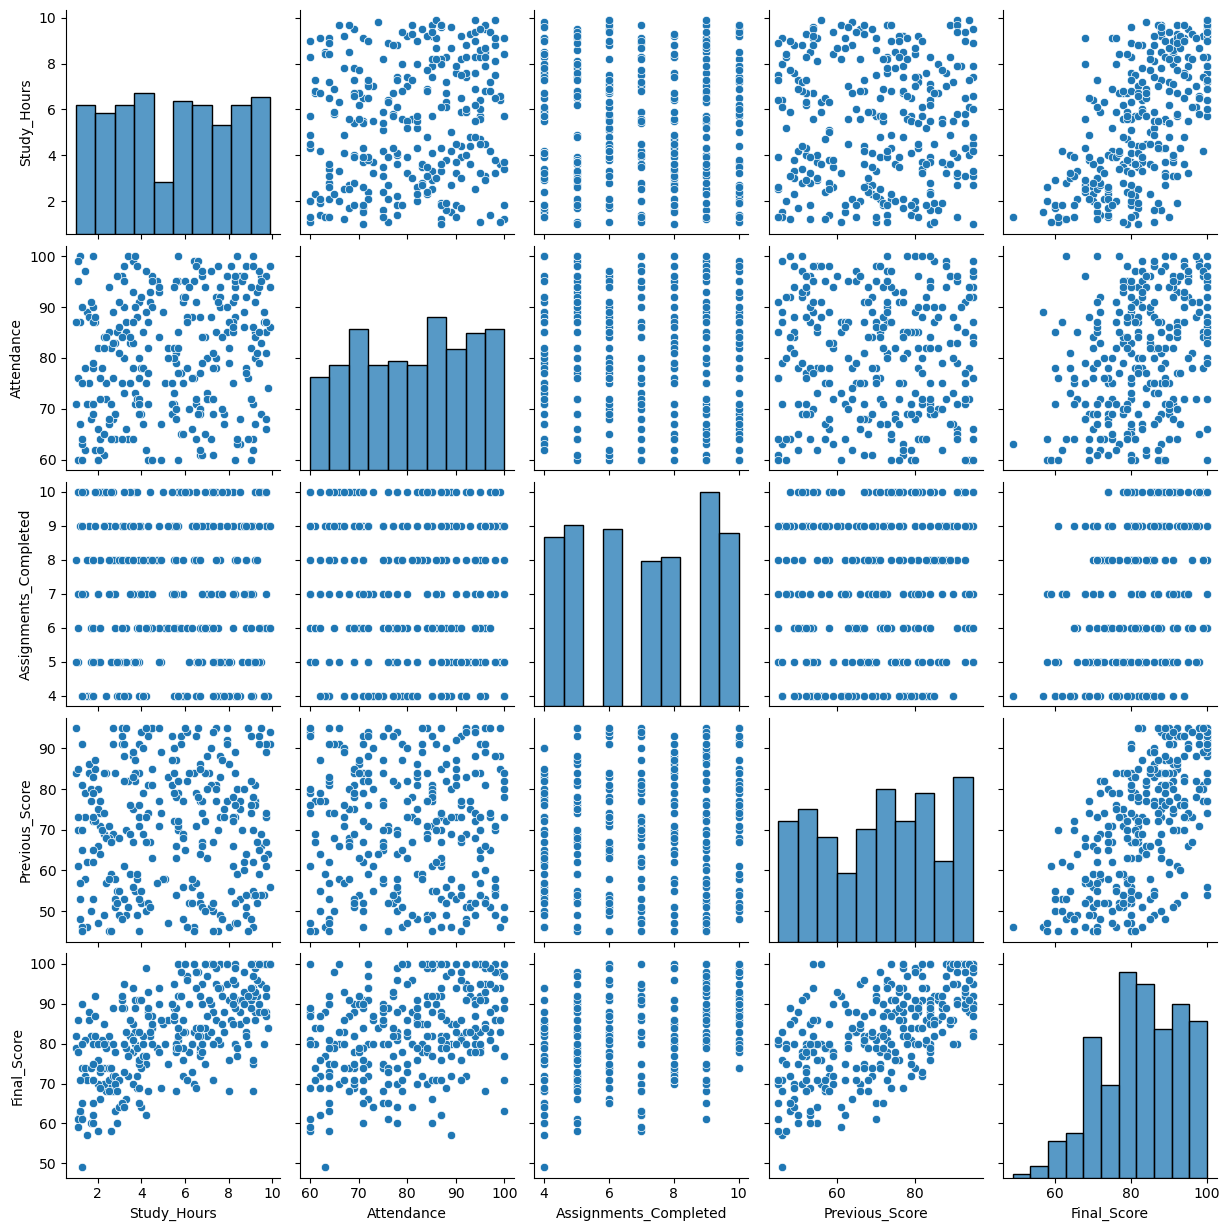

In [10]:
# lets do some visulization

import seaborn as sns
sns.pairplot(df)
plt.show()

In [11]:
df.corr()

,Study_Hours,Attendance,Assignments_Completed,Previous_Score,Final_Score
Study_Hours,1.000000,0.162459,-0.033409,0.007332,0.607182
Attendance,0.162459,1.000000,-0.030919,-0.009011,0.340046
Assignments_Completed,-0.033409,-0.030919,1.000000,0.134905,0.374441
Previous_Score,0.007332,-0.009011,0.134905,1.000000,0.625375
Final_Score,0.607182,0.340046,0.374441,0.625375,1.000000


In [29]:
X=df[['Study_Hours','Previous_Score','Attendance','Assignments_Completed']]
y=df['Final_Score']




In [30]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)

In [31]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.fit_transform(X_test)

In [25]:
from sklearn.linear_model import LinearRegression

regression=LinearRegression()

regression.fit(X_train,y_train)

LinearRegression()

In [32]:
y_pred=regression.predict(X_test)

In [42]:
from sklearn.metrics import mean_absolute_error

mae=mean_absolute_error(y_test,y_pred)
mae

2.243625417708005

In [ ]:
#for cross validation 
from sklearn.model_selection import cross_val_score

validation_score=cross_val_score(regression,X_train,y_train,scoring='neg_mean_squared_error',cv=5)

In [40]:
np.mean(validation_score)

np.float64(-10.362140801884674)

In [43]:
from sklearn.metrics import r2_score

r_square=r2_score(y_test,y_pred)
r_square

0.9266691314260792